EXPERIMENT 8: PERFORM ANALYSIS OF VARIANCE (ANOVA) ON IRIS DATA SET

In [2]:
import numpy as np
import pandas as pd
import matplotlib as plt
import seaborn as sns
#loading the datasets from sklearn
from sklearn.datasets import load_iris
#stats--> mean,median,mode
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [10]:
#load iris dataset
iris = load_iris()

#create DataFrame
df=pd.DataFrame(iris.data,columns=["sepal_length","sepal_width","petal_length","petal_width"])

#Add target/species column
df["target"] = iris.target

#Convert numerical target into species names
df["species"] = df["target"].map({
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
})

In [26]:
print("First 5 records:")
print(df.head())

print("\n Dataset Shape:")
print(df.shape)

print("\n Dataset Information:")
print(df.info())

print("\n Statistical Description:")
print(df.describe())

First 5 records:
   sepal_length  sepal_width  petal_length  petal_width  target species
0           5.1          3.5           1.4          0.2       0  Setosa
1           4.9          3.0           1.4          0.2       0  Setosa
2           4.7          3.2           1.3          0.2       0  Setosa
3           4.6          3.1           1.5          0.2       0  Setosa
4           5.0          3.6           1.4          0.2       0  Setosa

 Dataset Shape:
(150, 6)

 Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   target        150 non-null    int64  
 5   species       150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB
None

 

AttributeError: module 'matplotlib' has no attribute 'show'

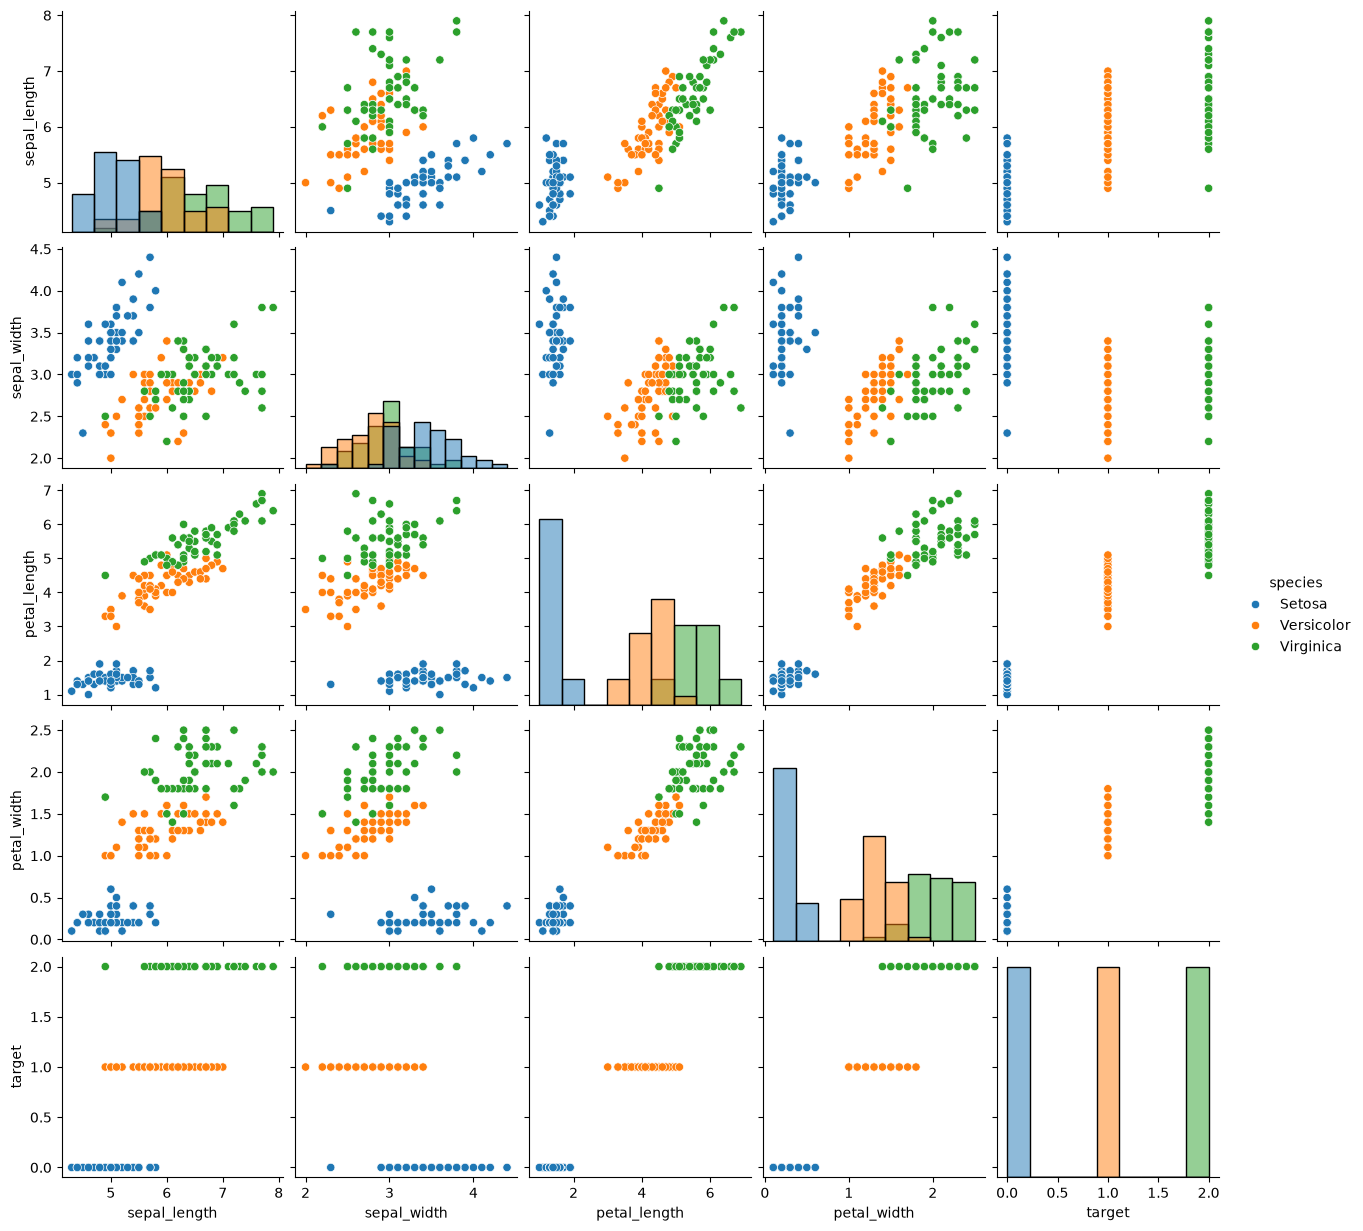

In [9]:
#visualise iris dataset
sns.pairplot(df,hue="species",diag_kind="hist")
plt.show()

In [5]:
# calculate mean sepal width for each species

print("\n mean sepal width by species:")

mean_values = df.groupby("species")["sepal_width"].mean()

print(mean_values)


 mean sepal width by species:
species
Setosa        3.428
Versicolor    2.770
Virginica     2.974
Name: sepal_width, dtype: float64


In [6]:
# check normality using shapiro-wilk test

for species in df["species"].unique():

    data = df[df["species"] == species]["sepal_width"]

    statistic, p_value = stats.shapiro(data)

    print(
    f"(species):"
    f"statistic = {statistic:.4f},"
    f"p_value = {p_value:.4f}"
    )

(species):statistic = 0.9717,p_value = 0.2715
(species):statistic = 0.9741,p_value = 0.3380
(species):statistic = 0.9674,p_value = 0.1809


In [7]:
# check equality of variances using levene's test

setosa = df[df["species"] == "Setosa"]["sepal_width"]

versicolor = df[df["species"] == "Versicolor"]["sepal_width"]

virginica = df[df["species"] == "Virginica"]["sepal_width"]

levene_stat, levene_p = stats.levene(
    setosa,
    versicolor,
    virginica
)

print("\nLevene's Test:")
print("Statistic =", levene_stat)
print("P-value =", levene_p)


Levene's Test:
Statistic = 0.5902115655853319
P-value = 0.5555178984739083


In [11]:
# perform one-way ANOVA

f_value, p_value = stats.f_oneway(setosa,versicolor,virginica)
print("\n One-way ANOVA Results:")
print("F-value =", f_value)
print("P-value =", p_value)


 One-way ANOVA Results:
F-value = 49.160040089612075
P-value = 4.492017133309084e-17


In [8]:
# Interpret ANOVA results

alpha = 0.05

print("\n ANOVA Interpretation:")

if p_value < alpha:
    print("Reject the Null Hypothesis.")
    print("There is a statiscally significant difference between the mean sepal widths of the three species."
         )
else:
    print("Fail to reject the Null hypothesis.")
    print("There is no statiscally significant difference between the mean sepal widths of the three species."
          )


 ANOVA Interpretation:
Fail to reject the Null hypothesis.
There is no statiscally significant difference between the mean sepal widths of the three species.
